In [1]:
import pandas as pd
from pandas import DataFrame  as df

#데이터 불러오기 시간이랑 트윗 텍스트만
Data = pd.read_csv("../02_대출도서_분석/청년층과 노년층 모두 많이 대출한 책(csv).csv")

Data

,검색어,저자,책소개
0,불편한 편의점,김호연,“근데 이게 마지막 술이에요. 이거 먹고 술 끊는 조건으로 우리 가게 일 좀 봐줘요...
1,물고기는 존재하지 않는다,룰루 밀러,‘혼돈’만이 우리의 유일한 지배자라고 아버지는 내게 알려주었다. 혼돈이라는 막무가내...
2,아버지의 해방일지,정지아,아버지가 죽었다. 전봇대에 머리를 박고. 평생을 정색하고 살아온 아버지가 전봇대에 ...
3,홍학의 자리,정해연,“이 행복이 영원할 거라고 생각한 적은 없었다.\n그러나 이런 끝을 상상한 적도 없...
4,밝은 밤,최은영,왜 개새끼라고 하나. 개가 사람한테 너무 잘해줘서 그런 거 아닌가. 아무 조건도 없...
5,지구 끝의 온실,김초엽,아영은 그렇게 느리고 꾸물거리는 것들이 멀리 퍼져 나가는 과정을 지켜보는 것이 좋았...
6,달러구트 꿈 백화점,이미예,“저는 세 번째 제자의 선택이 잘 이해되지 않았어요. 첫 번째 제자가 다스리기로 한...
7,도둑맞은 집중력,요한 하리,그는 집중력 문제의 증가를 비만율의 증가에 비유하는 방식이 이해에 도움이 될 수 있...
8,아주 희미한 빛으로도,최은영,"나의 결핍을 안고서 그것을 너무 미워하지도, 너무 가여워하지도 않고 그저 하루하루를..."
9,세이노의 가르침,세이노(SayNo),삶이 그대를 속이면 분노하라.\n---「첫 문장」중에서\n\n인생은 자전거와 같다....


In [2]:
Data.책소개 = Data.책소개.astype(str)

In [5]:
import pandas as pd
import numpy as np

# 데이터 프레임의 'text' 열의 값들을 str 형식으로 바꾸기
Data['책소개'] = Data['책소개'].astype(str)

# 한글이 아니면 빈 문자열로 바꾸기
Data['책소개'] = Data['책소개'].str.replace('[^ㄱ-ㅎㅏ-ㅣ가-힣]', ' ', regex=True)

# 빈 문자열을 NAN 값으로 바꾸기
Data['책소개'] = Data['책소개'].replace({'': np.nan})
Data['책소개'] = Data['책소개'].replace(r'^\s*$', np.nan, regex=True)

# NAN이 있는 행은 삭제
Data.dropna(subset=['책소개'], how='any', inplace=True)

# 인덱스 차곡차곡
Data = Data.reset_index(drop=True)

# 데이터 프레임에 null 값이 있는지 확인
print(Data.isnull().values.any())


False


In [4]:
from konlpy.tag import Okt
import pandas as pd
import numpy as np

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.extend([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 중복 제거
data_word = list(set(data_word))

# 결과를 데이터프레임으로 변환
nouns_df = pd.DataFrame(data_word, columns=['명사'])

# 데이터프레임 출력
print(nouns_df)

       명사
0      부자
1      실존
2     스스로
3      서구
4     평상시
...   ...
1859  판가름
1860   저번
1861   이모
1862   정해
1863  이제야

[1864 rows x 1 columns]


In [7]:
import pandas as pd
from konlpy.tag import Okt
import gensim
from gensim.corpora import Dictionary
import re
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Okt 객체 생성
okt = Okt()

# 텍스트 데이터를 리스트로 변환
Data_list = Data['책소개'].values.tolist()

# 리스트를 요소별로(책소개 하나) 가져와서 명사만 추출한 후 리스트로 저장
data_word = []
for text in Data_list:
    try:
        nouns = okt.nouns(text)
        # 길이가 2 이상인 명사만 추가
        data_word.append([noun for noun in nouns if len(noun) > 1])
    except Exception as e:
        continue

# 사전 생성
id2word = Dictionary(data_word)

# 단어 빈도 필터링
id2word.filter_extremes(no_below=5, no_above=0.5)  # 5회 이하로 등장하는 단어와 상위 50% 단어 필터링

# 코퍼스 생성
corpus = [id2word.doc2bow(doc) for doc in data_word]

# LDA 모델 설정
num_topics = 5  # 토픽 개수 설정
lda_model = gensim.models.LdaModel(
    corpus,
    num_topics=num_topics,
    id2word=id2word,
    passes=30,
    random_state=1000,
    alpha='auto',  # alpha 파라미터 자동 설정
    eta='auto'     # eta 파라미터 자동 설정
)

# 결과를 데이터프레임으로 변환
topics = []
for idx, topic in lda_model.show_topics(formatted=False):
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    topic_words = [word for word, _ in topic_words]  # 단어만 추출
    topics.append((idx, ", ".join(topic_words)))

# 데이터프레임 생성
topics_df = pd.DataFrame(topics, columns=['토픽 번호', '주요 단어'])

# 데이터프레임 출력 
print(topics_df)

# 각 토픽의 상위 n개의 단어 출력
n = 10  # 상위 n개의 단어 수
for idx, topic in lda_model.show_topics(num_topics=num_topics, num_words=n, formatted=False):
    print(f"토픽 {idx + 1}:")
    topic_words = sorted(topic, key=lambda x: x[1], reverse=True)  # 비중에 따라 단어 정렬
    for word, weight in topic_words:
        print(f"{word}: {weight:.4f}")
    print("\n")

   토픽 번호                                     주요 단어
0      0  당신, 스스로, 자기, 정도, 상태, 대한, 방법, 이야기, 시절, 자리
1      1   어쩌면, 평생, 모두, 누구, 선택, 아주, 절대, 정말, 다른, 사실
2      2    이름, 사실, 다른, 동안, 보고, 실제, 세계, 이해, 아주, 상태
3      3   그것, 인간, 상처, 기억, 세상, 사랑, 대부분, 인생, 불행, 존재
4      4  그녀, 당신, 이야기, 인생, 위해, 누군가, 기분, 계속, 사랑, 기억
토픽 1:
당신: 0.3177
스스로: 0.0447
자기: 0.0310
정도: 0.0307
상태: 0.0307
대한: 0.0307
방법: 0.0307
이야기: 0.0204
시절: 0.0179
자리: 0.0175


토픽 2:
어쩌면: 0.0833
평생: 0.0573
모두: 0.0573
누구: 0.0573
선택: 0.0573
아주: 0.0313
절대: 0.0312
정말: 0.0312
다른: 0.0312
사실: 0.0312


토픽 3:
이름: 0.0519
사실: 0.0470
다른: 0.0470
동안: 0.0376
보고: 0.0365
실제: 0.0364
세계: 0.0349
이해: 0.0288
아주: 0.0286
상태: 0.0285


토픽 4:
그것: 0.0718
인간: 0.0596
상처: 0.0541
기억: 0.0445
세상: 0.0383
사랑: 0.0376
대부분: 0.0287
인생: 0.0279
불행: 0.0262
존재: 0.0261


토픽 5:
그녀: 0.0713
당신: 0.0465
이야기: 0.0461
인생: 0.0416
위해: 0.0339
누군가: 0.0304
기분: 0.0230
계속: 0.0229
사랑: 0.0228
기억: 0.0224




In [6]:
font = 'DoHyeon-Regular.ttf'

In [8]:
import pyLDAvis
import pyLDAvis.gensim_models

# pyLDAvis를 사용한 시각화
vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, id2word)
pyLDAvis.display(vis)

C:\Users\leeju\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
C:\Users\leeju\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(
C:\Users\leeju\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:77: DeprecationWarning: backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.
  warnings.warn(


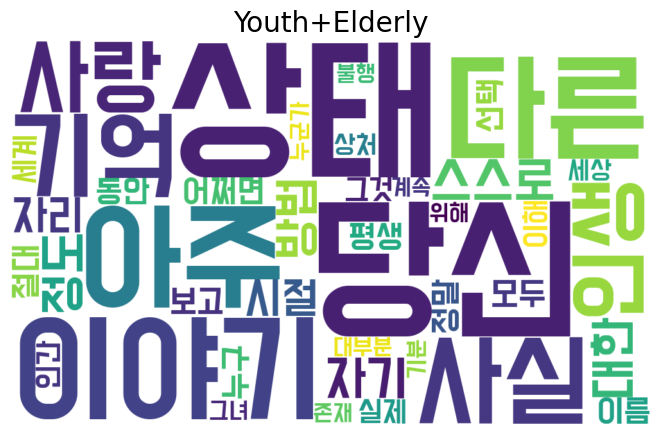

In [11]:
# 워드클라우드 생성
word_string = ", ".join(topics_df['주요 단어'].tolist())

font = 'DoHyeon-Regular.ttf'  # 한글 폰트 경로

wordcloud = WordCloud(
    font_path=font,
    width=1000,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=200,
    random_state=42
).generate(word_string)

# 워드클라우드 시각화
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Youth+Elderly', fontsize=20)
plt.show()

<청년+노년>  
토픽 0 : 성찰
토픽 1 : 선택
토픽 2 : 이해
토픽 3 : 역경
토픽 4 : 공감